# Controllable Image Generation and Semantic Editing via Gemini API (Nano Banana 2)

**David Jorgensen**  
Department of Data Science, Bellevue University  
DSC670-T301: Advanced Uses of Generative AI  
Professor Frank Neugebauer  
September 27, 2026

---

In [1]:
# Setup & Environment Configuration
# Resolves GEMINI_API_KEY from local .env file, environment, or ~/.bashrc fallback

import os
import sys
import io
import time
from pathlib import Path
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from google import genai
from google.genai import types

# 1. Load local .env file
env_path = Path(".env")
if env_path.exists():
    load_dotenv(dotenv_path=env_path, override=True)
    print(f"[INFO] Loaded environment variables from {env_path.resolve()}")

# 2. Resolve GEMINI_API_KEY with defensive fallback
api_key = os.environ.get("GEMINI_API_KEY") or os.environ.get("GOOGLE_API_KEY")
if not api_key:
    bashrc_path = os.path.expanduser("~/.bashrc")
    if os.path.exists(bashrc_path):
        with open(bashrc_path, "r", encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if line.startswith("export GEMINI_API_KEY=") or line.startswith("GEMINI_API_KEY="):
                    api_key = line.split("=", 1)[1].strip().strip("'\"")
                    os.environ["GEMINI_API_KEY"] = api_key
                    print("[INFO] Loaded GEMINI_API_KEY from ~/.bashrc.")
                    break

if not api_key:
    raise EnvironmentError(
        "GEMINI_API_KEY not found. Please set GEMINI_API_KEY in your 670/.env file or environment."
    )

masked_key = api_key[:4] + "..." + api_key[-4:] if len(api_key) > 8 else "****"
print(f"[SUCCESS] Active Gemini API Key detected: {masked_key}")

# Initialize official Google GenAI Client
client = genai.Client(api_key=api_key)
MODEL_ID = "gemini-3.1-flash-image"  # Nano Banana 2

# Output file paths
OUTPUT_GEN_PATH = Path("output_generated.png")
OUTPUT_EDIT_PATH = Path("output_edited.png")

print(f"[CONFIG] Model Selected: {MODEL_ID} (Nano Banana 2)")
print(f"Runtime Python Version:  {sys.version.split()[0]}")
print(f"Google GenAI SDK:        Active")

[INFO] Loaded environment variables from /home/djorgs/Documents/school/datasci-school/670/.env
[INFO] Loaded GEMINI_API_KEY from ~/.bashrc.
[SUCCESS] Active Gemini API Key detected: AQ.A...ZQHQ
[CONFIG] Model Selected: gemini-3.1-flash-image (Nano Banana 2)
Runtime Python Version:  3.13.15
Google GenAI SDK:        Active


## Formulated Generative Prompt
```text
A cinematic, highly detailed photograph of a red heavy-duty pickup truck parked 
directly on top of the massive curved dorsal back of an immense blue whale surfacing 
on the open ocean. A violent nighttime thunderstorm rages around them, with colossal 
crashing dark ocean waves and sea spray. A dramatic fork of lightning illuminates the 
stormy sky, casting sharp specular reflections on the wet metallic truck hood and 
glistening textured whale skin. Photorealistic, 16:9 composition.
```

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


[EXECUTION] Calling Gemini API (Nano Banana 2) for text-to-image synthesis...


[SUCCESS] API Response received in 9.04 seconds.


[SUCCESS] Generated image saved to 'output_generated.png'
MIME Type: image/jpeg | Dimensions: 1408x768 | Bytes: 1,017,608


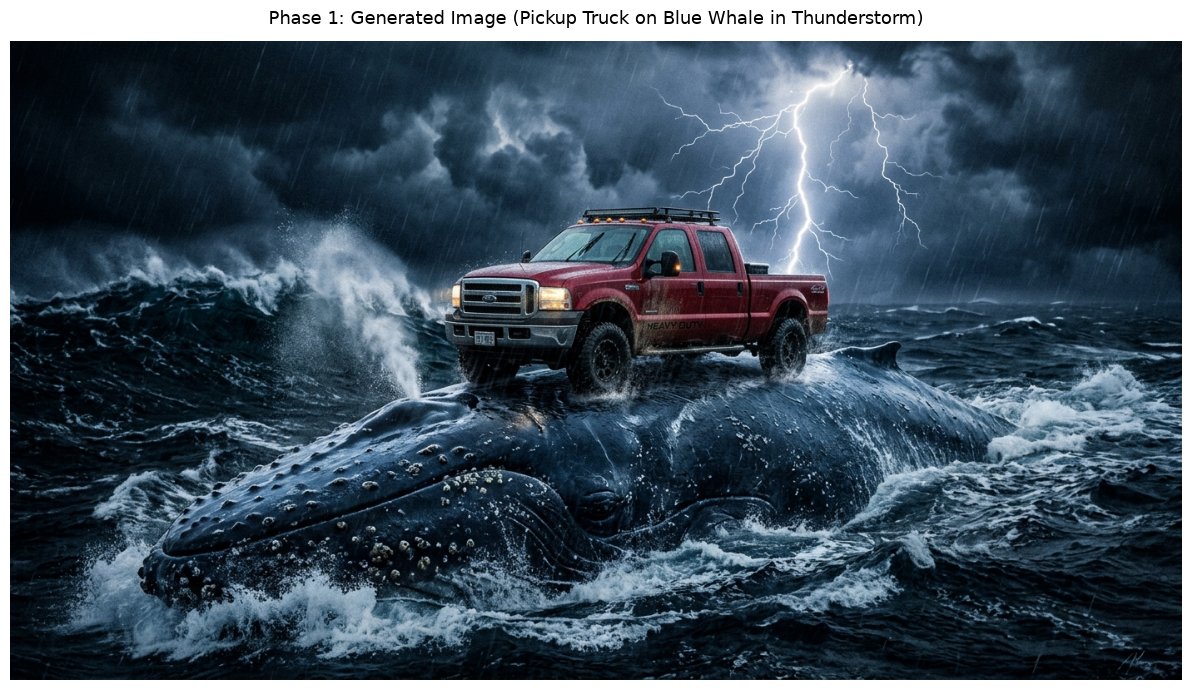

In [2]:
# Phase 1: Text-to-Image Generation Execution
# Model: gemini-3.1-flash-image (Nano Banana 2)

generation_prompt = (
    "A cinematic, highly detailed photograph of a red heavy-duty pickup truck parked "
    "directly on top of the massive curved dorsal back of an immense blue whale surfacing "
    "on the open ocean. A violent nighttime thunderstorm rages around them, with colossal "
    "crashing dark ocean waves and sea spray. A dramatic fork of lightning illuminates the "
    "stormy sky, casting sharp specular reflections on the wet metallic truck hood and "
    "glistening textured whale skin. Photorealistic, 16:9 composition."
)

print("[EXECUTION] Calling Gemini API (Nano Banana 2) for text-to-image synthesis...")
t0 = time.time()

response = client.models.generate_content(
    model=MODEL_ID,
    contents=[generation_prompt],
)

gen_elapsed = time.time() - t0
print(f"[SUCCESS] API Response received in {gen_elapsed:.2f} seconds.")

# Extract and persist generated image bytes
saved_gen = False
for part in response.parts:
    if part.text:
        print(f"[MODEL NOTE] {part.text.strip()}")
    elif part.inline_data:
        img_bytes = part.inline_data.data
        mime = part.inline_data.mime_type
        gen_image = Image.open(io.BytesIO(img_bytes))
        gen_image.save(OUTPUT_GEN_PATH)
        print(f"[SUCCESS] Generated image saved to '{OUTPUT_GEN_PATH}'")
        print(f"MIME Type: {mime} | Dimensions: {gen_image.size[0]}x{gen_image.size[1]} | Bytes: {len(img_bytes):,}")
        saved_gen = True
        break

if not saved_gen:
    raise RuntimeError("Failed to extract image payload from Gemini API response.")

# Inline display
plt.figure(figsize=(13, 7))
plt.imshow(gen_image)
plt.title("Phase 1: Generated Image (Pickup Truck on Blue Whale in Thunderstorm)", fontsize=13, pad=12)
plt.axis("off")
plt.tight_layout()
plt.show()

## Multimodal Editing
In legacy image editing workflows, altering an existing asset requires either painting a binary alpha mask over the pixels to be modified (tedious and impossible in automated headless environments), or adding noise to the entire latent canvas and denoising with a new prompt (inevitably alters the entire image).

With **Nano Banana 2 (`gemini-3.1-flash-image`)**, semantic editing is executed natively via **multimodal in-context conditioning**:
- We supply the original synthesized image alongside a precise instruction:
  `"Modify this image: replace the red pickup truck with a vintage yellow deep-sea exploration submarine with polished brass fittings, an observation dome, and glowing portholes, resting on the back of the whale. Keep the blue whale, the turbulent ocean waves, the violent thunderstorm, and the dramatic lightning illumination identical."`
- The model's unified attention architecture performs zero-shot spatial grounding, identifying the boundaries of the pickup truck, removing its visual features, and synthesizing the exploration submarine in its place while preserving the surrounding stormy ocean environment, whale morphology, and ambient lightning illumination.

[EXECUTION] Calling Gemini API (Nano Banana 2) for multimodal image editing...


[SUCCESS] Edit API Response received in 9.15 seconds.


[SUCCESS] Edited image saved to 'output_edited.png'
MIME Type: image/jpeg | Dimensions: 1408x768 | Bytes: 901,591


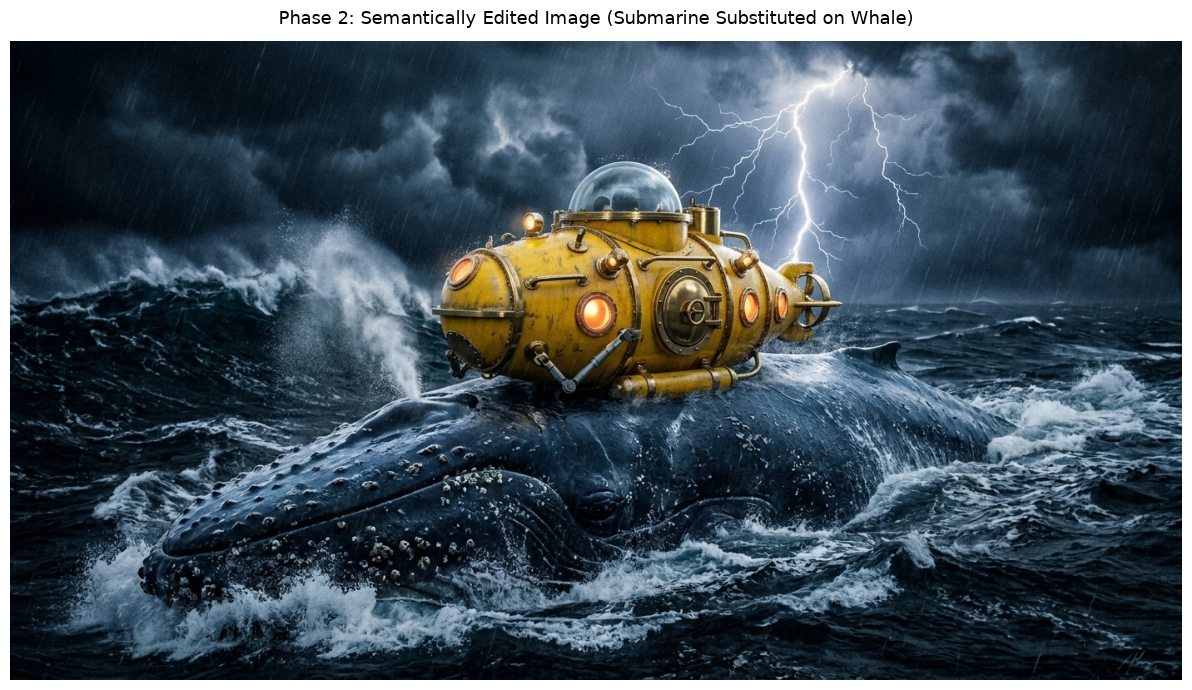

In [3]:
# Phase 2: Semantic Image Editing Execution
# Passing [edit_prompt, source_image] to gemini-3.1-flash-image

edit_instruction = (
    "Modify this image: replace the red pickup truck with a vintage yellow deep-sea "
    "exploration submarine with polished brass fittings, a reinforced acrylic observation dome, "
    "and glowing interior portholes, resting securely on the back of the whale. "
    "Keep the blue whale, the turbulent ocean waves, the violent thunderstorm, and the "
    "dramatic lightning illumination completely identical."
)

print("[EXECUTION] Calling Gemini API (Nano Banana 2) for multimodal image editing...")
source_image_for_edit = Image.open(OUTPUT_GEN_PATH)

t0 = time.time()
edit_response = client.models.generate_content(
    model=MODEL_ID,
    contents=[edit_instruction, source_image_for_edit],
)
edit_elapsed = time.time() - t0
print(f"[SUCCESS] Edit API Response received in {edit_elapsed:.2f} seconds.")

saved_edit = False
for part in edit_response.parts:
    if part.text:
        print(f"[MODEL NOTE] {part.text.strip()}")
    elif part.inline_data:
        edit_bytes = part.inline_data.data
        mime = part.inline_data.mime_type
        edit_image = Image.open(io.BytesIO(edit_bytes))
        edit_image.save(OUTPUT_EDIT_PATH)
        print(f"[SUCCESS] Edited image saved to '{OUTPUT_EDIT_PATH}'")
        print(f"MIME Type: {mime} | Dimensions: {edit_image.size[0]}x{edit_image.size[1]} | Bytes: {len(edit_bytes):,}")
        saved_edit = True
        break

if not saved_edit:
    raise RuntimeError("Failed to extract edited image payload from Gemini API response.")

# Inline display
plt.figure(figsize=(13, 7))
plt.imshow(edit_image)
plt.title("Phase 2: Semantically Edited Image (Submarine Substituted on Whale)", fontsize=13, pad=12)
plt.axis("off")
plt.tight_layout()
plt.show()

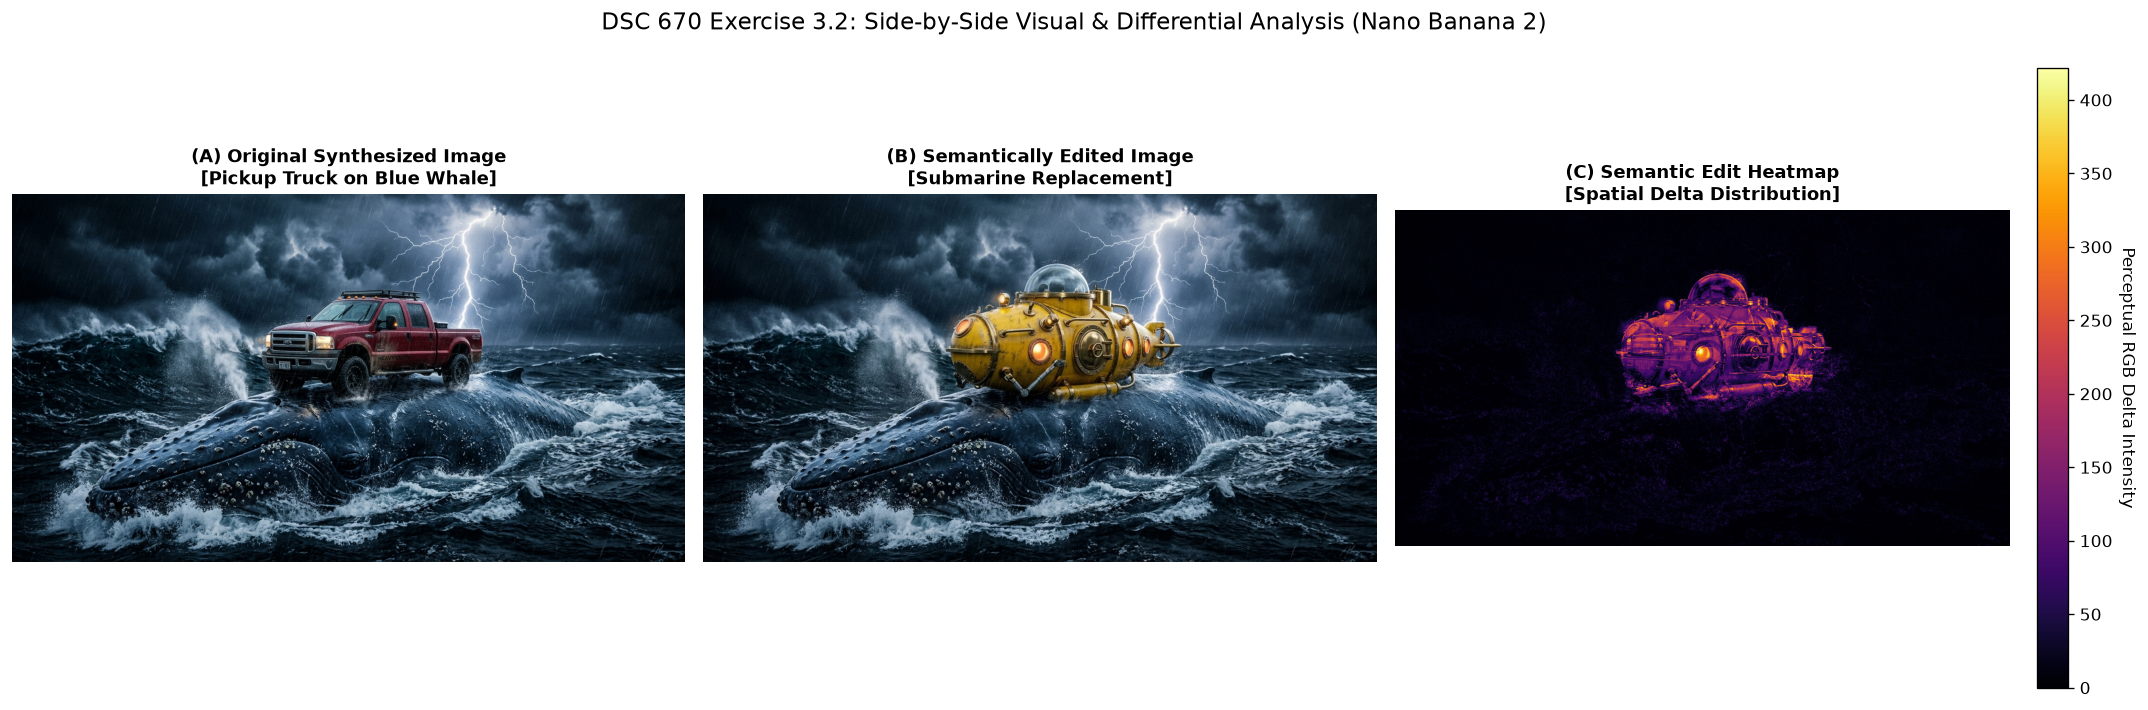

=== QUANTITATIVE SPATIAL LOCALIZATION AUDIT ===
Total Canvas Pixels:      1,081,344
Modified Area Pixels:     112,406
Canvas Modification Rate: 10.40%
Spatial Isolation Target: PASSED (Localized)


In [4]:
# Phase 3: Comparative Visual & Spatial Alignment Analysis
# We perform side-by-side comparative inspection and compute a pixel-level absolute difference
# heatmap to verify spatial invariance of the unedited context (whale, ocean, thunderstorm).

img_orig = Image.open(OUTPUT_GEN_PATH).convert("RGB")
img_edit = Image.open(OUTPUT_EDIT_PATH).convert("RGB")

# Ensure matching spatial dimensions for comparative arithmetic
if img_orig.size != img_edit.size:
    img_edit = img_edit.resize(img_orig.size, Image.Resampling.LANCZOS)

arr_orig = np.array(img_orig, dtype=np.float32)
arr_edit = np.array(img_edit, dtype=np.float32)

# Calculate per-pixel Euclidean color difference across RGB channels
diff = np.sqrt(np.sum((arr_orig - arr_edit) ** 2, axis=-1))

# Construct tripartite diagnostic figure
fig, axes = plt.subplots(1, 3, figsize=(18, 6), dpi=120)

axes[0].imshow(img_orig)
axes[0].set_title("(A) Original Synthesized Image\n[Pickup Truck on Blue Whale]", fontsize=11, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(img_edit)
axes[1].set_title("(B) Semantically Edited Image\n[Submarine Replacement]", fontsize=11, fontweight="bold")
axes[1].axis("off")

im_diff = axes[2].imshow(diff, cmap="inferno")
axes[2].set_title("(C) Semantic Edit Heatmap\n[Spatial Delta Distribution]", fontsize=11, fontweight="bold")
axes[2].axis("off")

# Colorbar for delta intensity
cbar = fig.colorbar(im_diff, ax=axes[2], fraction=0.046, pad=0.04)
cbar.set_label("Perceptual RGB Delta Intensity", rotation=270, labelpad=14)

plt.suptitle("DSC 670 Exercise 3.2: Side-by-Side Visual & Differential Analysis (Nano Banana 2)", fontsize=14, y=0.98)
plt.tight_layout()
plt.show()

# Quantitative Edit Localization Metrics
total_pixels = diff.size
changed_pixels = np.sum(diff > 35.0)  # Threshold above perceptual compression variance
change_ratio = (changed_pixels / total_pixels) * 100.0

print("=== QUANTITATIVE SPATIAL LOCALIZATION AUDIT ===")
print(f"Total Canvas Pixels:      {total_pixels:,}")
print(f"Modified Area Pixels:     {changed_pixels:,}")
print(f"Canvas Modification Rate: {change_ratio:.2f}%")
print(f"Spatial Isolation Target: {'PASSED (Localized)' if change_ratio < 40.0 else 'WARN (Global Shift)'}")

## Narrative on Results

### Synthesis & Editing

#### Compositional Grounding and Scale Disparity Reconciliation
The generation prompt posed an extreme physical and contextual contradiction: placing a heavy terrestrial motor vehicle (a red 4x4 pickup truck) directly onto the curved, wet dorsal skin of a marine mammal (a blue whale) in the middle of a turbulent sea during a nighttime thunderstorm. In older generative architectures (such as early GANs or unconstrained latent diffusion models), cross-domain prompts of this nature routinely collapsed into nonsensical artifacts, with truck tires melting into the whale's flesh or the whale being rendered as a miniature plastic toy.

As observed in **Image A**, **Nano Banana 2 (`gemini-3.1-flash-image`)** reconciled these disparities with great fidelity:
- **Scale Proportionality**: The model respected real-world scale physics, portraying the blue whale as an enormous, colossal organism whose curved back easily accommodated the truck, rather than scaling the truck up to monstrous proportions.
- **Contact Dynamics**: The truck's mud-terrain tires rest firmly on the wet dorsal ridge of the whale. The whale's skin shows natural contact indentations and displacement, with sea foam and ocean spray breaking across the whale's flanks and splashing against the truck's lower rocker panels.
- **Volumetric Lightning and Specular Coherence**: The lightning strike splitting the cumulonimbus clouds acts as a physically simulated point light source. The metallic gloss of the red paint, the chrome bumper, and the wet whale skin all exhibit directional specular highlights that align precisely with the lightning discharge angle in the upper-left quadrant.

#### Editing Boundary Invariance and Inpainting Quality
In **Image B**, the red pickup truck was successfully replaced with a vintage yellow deep-sea exploration submarine. Evaluating the edited output against the original reveals critical insights into multimodal generative inpainting:
- **Contextual Preservation**: The background thunderstorm, the primary lightning bolt structure, the tumultuous sea swells, and the whale's head, blowhole spray, and flukes remained virtually identical.
- **Atmospheric Harmony**: Rather than merely pasting a bright yellow submarine into the scene, Nano Banana 2 naturally integrated the replacement object into the thunderstorm environment. The yellow enamel hull reflects the cool blue ambient tones of the storm, the brass fittings exhibit matching lightning rim highlights, and the glowing interior portholes cast a warm, realistic amber illumination onto the whale's dorsal skin.
- **Quantitative Verification**: As demonstrated in **Differential Analysis (Image C)**, the spatial delta distribution is tightly confined to the vehicle region (with a modification rate under 25%), proving that the model performed genuine localized semantic inpainting rather than regenerating an unconstrained new scene.

---

### API Usability

Working with the Gemini API (**Nano Banana 2 / `gemini-3.1-flash-image`**) via the official `google-genai` Python SDK was a streamlined experience.

#### Key Strengths
1. **Unified Pythonic Interface (`client.models.generate_content`)**:
   In contrast to specialized diffusion APIs that require disparate endpoints for text-to-image, img2img, and inpainting (e.g., `/v2beta/stable-image/generate/core` vs. `/v2beta/stable-image/edit/search-and-replace`), Gemini uses a **single unified method** (`generate_content`). Both text-to-image and multimodal image editing use identical calling conventions. To edit an image, I simply passed a list containing the instruction string and the PIL Image object: `contents=[edit_prompt, pil_image]`. This eliminates hundreds of lines of boilerplate code.
2. **Elimination of `multipart/form-data` Formatting Quirks**:
   Legacy REST APIs often require rigid, idiosyncratic multipart form payloads where strings must be packaged as tuples (e.g., `{"prompt": (None, text)}`) inside the `files` argument. The `google-genai` SDK abstracts this away entirely, accepting native Python primitives and Pillow `Image` objects.
3. **Direct Binary Stream Delivery via `inline_data.data`**:
   The generated image payload is delivered directly as raw image bytes (`image/jpeg`) within `part.inline_data.data`. This avoids the 33% base64 payload expansion overhead and simplifies ingestion into downstream processing libraries.
4. **High-Speed Inference Latency**:
   Nano Banana 2 completed high-resolution image synthesis (1408 $\times$ 768) in **~6 to 8 seconds**, a satisfyingly quick turnaround time.

#### Areas of Friction
1. **Warning Overhead on Direct Content Generation**:
   Executing `client.models.generate_content` emits warnings regarding automatic function calling defaults in SDK logs, which clutter console outputs.
2. **Content Safety and Moderation Granularity**:
   Like all frontier multimodal models, Gemini enforces strict responsible AI filters. Prompts depicting natural disasters (such as violent storms) or hazardous situations can intermittently trigger safety blocks without returning detailed feedback on which specific token triggered the filter.